# Trwałość kwalifikacji do Ligi Mistrzów — dynamiczny probit CRE

**Pytanie:** na ile prawdopodobieństwo awansu klubu do Ligi Mistrzów zależy od tego, że
awansował rok wcześniej, a na ile od jego funduszu płac?

**Panel:** klub × sezon, cztery ligi (Premier League, Bundesliga, La Liga, Serie A),
sezony 2013/14 – 2023/24.

**Zmienna objaśniana:** `Y = 1`, gdy klub zajął miejsce w pierwszej czwórce swojej ligi.

**Metoda:** dynamiczny probit z korelowanymi efektami losowymi (CRE) w ujęciu
Wooldridge'a — opóźniona zmienna zależna, warunek początkowy `Y_0` i średnie
wewnątrzklubowe regresorów (urządzenie Mundlaka), z błędami standardowymi
klastrowanymi po klubie.

Logika obliczeniowa jest w `src/`; notebook ją wywołuje i opisuje.

In [1]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd

_here = Path.cwd().resolve()
while not (_here / 'src' / 'data_load.py').is_file():
    if _here == _here.parent:
        raise RuntimeError(f'Nie znaleziono korzenia projektu startujac z {Path.cwd()}.')
    _here = _here.parent
sys.path.insert(0, str(_here))

from src import data_load, inference, model, pre_processing, visualisation as viz

warnings.filterwarnings('ignore')
pd.set_option('display.width', 170)
pd.set_option('display.max_columns', 40)
viz.setup_style()

print('Korzen projektu:', data_load.PROJECT_ROOT.name)
print('Pliki surowe:', sorted(p.name for p in data_load.RAW.glob('*.csv')))

Korzen projektu: panel-liga-mistrzow
Pliki surowe: ['club_games.csv', 'clubs.csv', 'games.csv', 'place_top4_ligi_2013_2023.csv', 'player_valuations.csv', 'transfers.csv']


## 1. Dane źródłowe

Dwa źródła, łączone po `club_id` i sezonie:

- **Transfermarkt** (`games`, `club_games`, `player_valuations`, `transfers`) — wyniki
  meczów, wyceny rynkowe zawodników i kwoty transferów.
- **fbref** (`place_top4_ligi_2013_2023.csv`) — roczne funduszu płac klubów, zebrane
  przez `notebooks/01_pobranie_plac.ipynb`.

Nazwy klubów różnią się między źródłami („Manchester Utd" kontra „Manchester United"),
więc mapowanie na `club_id` jest w `src/data_load.py` i zweryfikowane ręcznie. Liczba
niezmapowanych nazw jest wypisywana poniżej — każda z nich to utracone obserwacje.

In [2]:
games = data_load.load_games()
club_games = data_load.load_club_games()
valuations = data_load.load_valuations()
transfers = data_load.load_transfers()
wages = data_load.load_wages()

lg = data_load.league_games(games)
print(f'Mecze ligowe 4 lig: {len(lg)} '
      f'(sezony {data_load.SEASON_MIN}-{data_load.SEASON_MAX})')

Mecze ligowe 4 lig: 15906 (sezony 2013-2023)


## 2. Budowa panelu

Kolejne kroki, każdy w osobnej funkcji w `src/pre_processing.py`:

1. **Tabela ligowa** — punkty, bilans bramek i pozycja końcowa. Pozycja i `Y` są
   wyznaczane **w obrębie pary liga × sezon**; przy rankingu globalnym kluby słabszej
   ligi nigdy nie trafiłyby do pierwszej czwórki.
2. **Wartość rynkowa kadry** — suma ostatnich wycen zawodników **nie późniejszych niż
   1 lipca**, czyli przed rundą transferową, która jest już reakcją na poprzedni sezon.
3. **Fundusz płac** — miara finansowa główna. Waluta różni się między ligami, ale
   w logarytmach stała przelicznika jest pochłaniana przez efekt stały ligi.
4. **Regresory dodatkowe** — zmiana trenera, beniaminek, saldo transferowe w okienku
   letnim, udział w LM (opisowo).
5. **Zmienne CRE** — `Y_lag`, `Y_0`, średnie Mundlaka i lead-y do testu egzogeniczności.

Panel zapisuje się do `data/processed/`, więc modele da się powtórzyć bez wczytywania
65 MB danych surowych.

In [3]:
panel, unmatched = pre_processing.build_panel(
    games, club_games, valuations, transfers, wages, lg)

print(f'Rekordow plac: {len(wages)}; niezmapowanych nazw: {len(unmatched)}')
if len(unmatched):
    print('  UWAGA:', unmatched.to_dict('records'))

both = panel.dropna(subset=['log_wage', 'log_mv'])
print(f"Korelacja log(wage) vs log(market_value): "
      f"{both['log_wage'].corr(both['log_mv']):.3f} (n={len(both)})"
      f"  |  pokrycie plac: {panel['log_wage'].notna().mean():.0%}")
print('Zmiana trenera:', f"{panel['mgr_change'].mean():.0%},",
      'udzial w LM:', f"{panel['cl_part'].mean():.0%}")

Rekordow plac: 855; niezmapowanych nazw: 0
Korelacja log(wage) vs log(market_value): 0.775 (n=855)  |  pokrycie plac: 100%
Zmiana trenera: 37%, udzial w LM: 21%


In [4]:
est = pre_processing.to_estimation_frame(panel, save=True)

print(f"Proba estymacyjna: {len(est)} obs., {est['club_id'].nunique()} klubow, 4 ligi")
print(pre_processing.describe_panel(est).to_string())

Zapisano panel: panel_klub_sezon.csv (858 obserwacji)
Proba estymacyjna: 726 obs., 115 klubow, 4 ligi
                obs  klubow  kwal_rate
league                                
Bundesliga      169      26      0.231
La_Liga         187      30      0.214
Premier_League  186      31      0.215
Serie_A         184      28      0.217


## 3. Model główny: dynamiczny probit CRE

Specyfikacja (`src/model.CRE`):

```
Y ~ Y_lag + log_wage + Y_0 + mean_log_wage + C(season) + C(league)
```

- `Y_lag` — **zależność stanu**: czy sam fakt awansu w poprzednim sezonie podnosi szansę
  awansu w bieżącym, przy tym samym poziomie finansów.
- `Y_0` — warunek początkowy, bez którego `Y_lag` byłby obciążony efektem klubu.
- `mean_log_wage` — średnia wewnątrzklubowa funduszu płac. Rozdziela efekt **within**
  (zmiana płac w klubie) od **between** (trwały poziom zamożności klubu).

Błędy standardowe klastrowane po klubie, bo kolejne sezony tego samego klubu nie są
niezależne.

In [5]:
m_cre = model.fit_main(est)
print(m_cre.summary())
print(f'\nPseudo R2 = {m_cre.prsquared:.3f}; LLR p-value = {m_cre.llr_pvalue:.2e}')

                          Probit Regression Results                           
Dep. Variable:                      Y   No. Observations:                  726
Model:                         Probit   Df Residuals:                      709
Method:                           MLE   Df Model:                           16
Date:                Fri, 02 Oct 2026   Pseudo R-squ.:                  0.5029
Time:                        18:14:55   Log-Likelihood:                -189.70
converged:                       True   LL-Null:                       -381.62
Covariance Type:              cluster   LLR p-value:                 8.807e-72
                                  coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------
Intercept                     -29.8168      4.040     -7.380      0.000     -37.735     -21.898
C(season)[T.2015]               0.0161      0.355      0.045      0.964      -0.

### 3a. Punkt odniesienia: statyczny probit bez `Y_lag`

Model bez zależności stanu pokazuje, co się dzieje, gdy trwałość pozycji zostanie
pominięta: efekt bieżącego funduszu płac przejmuje na siebie to, co w rzeczywistości
jest trwałością stanu.

In [6]:
m_static = model.fit_static(est)
print(m_static.summary())

print('\nlog_wage: statyczny vs CRE')
print(f"  statyczny: {m_static.params['log_wage']:+.3f} "
      f"(p={m_static.pvalues['log_wage']:.3f})")
print(f"  CRE:       {m_cre.params['log_wage']:+.3f} "
      f"(p={m_cre.pvalues['log_wage']:.3f})")

                          Probit Regression Results                           
Dep. Variable:                      Y   No. Observations:                  726
Model:                         Probit   Df Residuals:                      712
Method:                           MLE   Df Model:                           13
Date:                Fri, 02 Oct 2026   Pseudo R-squ.:                  0.4500
Time:                        18:14:55   Log-Likelihood:                -209.89
converged:                       True   LL-Null:                       -381.62
Covariance Type:              cluster   LLR p-value:                 1.835e-65
                                  coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------
Intercept                     -33.4355      3.540     -9.445      0.000     -40.374     -26.497
C(season)[T.2015]              -0.0208      0.299     -0.069      0.945      -0.

## 4. Efekty cząstkowe i dekompozycja Mundlaka

W probicie współczynniki **nie są prawdopodobieństwami**. Interpretowalną wielkością jest
przeciętny efekt cząstkowy (AME): dla zmiennych zero-jedynkowych różnica dyskretna
Φ(·|1) − Φ(·|0) uśredniona po próbie, dla ciągłych pochodna.

Dekompozycja Mundlaka rozdziela efekt płac na część krótkookresową (`log_wage`) i trwałą
(`log_wage + mean_log_wage`).

In [7]:
sf = inference.ame(m_cre)
show = [n for n in ['Y_lag', 'log_wage', 'Y_0', 'mean_log_wage'] if n in sf.index]
print(sf.loc[show, ['AME', 'se', 'p']].round(3).to_string())

ape_ylag = inference.discrete_effect(m_cre, est, 'Y_lag')
print(f'\n>> APE Y_lag (roznica dyskretna): {ape_ylag:+.3f} '
      f"(p={m_cre.pvalues['Y_lag']:.3f})")

dec = inference.wage_decomposition(m_cre)
print(f">> Place, efekt krotkookresowy (within): {dec['within']:+.3f}")
print(f">> Place, czesc between (mean_log_wage):  {dec['between']:+.3f}")
print(f">> Place, efekt TRWALY (within+between):  {dec['trwaly']:+.3f} "
      f"-> +10% plac = {dec['trwaly_pp_na_10pct']:+.1f} pp")

                 AME     se      p
Y_lag          0.112  0.052  0.032
log_wage       0.004  0.055  0.942
Y_0            0.031  0.035  0.363
mean_log_wage  0.231  0.057  0.000

>> APE Y_lag (roznica dyskretna): +0.112 (p=0.008)
>> Place, efekt krotkookresowy (within): +0.004
>> Place, czesc between (mean_log_wage):  +0.231
>> Place, efekt TRWALY (within+between):  +0.235 -> +10% plac = +2.2 pp


## 5. Testy poprawności specyfikacji

Trzy testy, z których **jeden wypada negatywnie** — co jest wynikiem, nie usterką:

1. **Łączny test Mundlaka** (H0: efekt klubu nieskorelowany z regresorami, czyli RE
   wystarcza). Odrzucenie oznacza, że CRE jest konieczne.
2. **Link test Pregibona** — kwadrat predykcji liniowej nie powinien być istotny.
3. **Test ścisłej egzogeniczności** — istotny lead regresora oznacza feedback: fundusz
   płac reaguje na przeszłe wyniki. Zobacz ograniczenia w README.

In [8]:
chi2_m, p_m = inference.mundlak_test(m_cre)
print('>> Laczny test Mundlaka (H0: RE wystarczy):')
print(f'   chi2 = {chi2_m:.2f}, df = 2, p = {p_m:.2e} -> '
      + ('ODRZUCENIE H0 -> CRE konieczne (RE obciazony)' if p_m < 0.05
         else 'brak podstaw do odrzucenia RE'))

p_link = inference.link_test(m_cre, est)
print('\n>> Link test (Pregibon), istotnosc kwadratu predykcji liniowej:')
print(f'   _xb2: p = {p_link:.3f} -> '
      + ('postac funkcyjna OK (brak dowodu zlej specyfikacji)' if p_link > 0.1
         else 'SYGNAL zlej postaci funkcyjnej'))

>> Laczny test Mundlaka (H0: RE wystarczy):


   chi2 = 14.75, df = 2, p = 6.27e-04 -> ODRZUCENIE H0 -> CRE konieczne (RE obciazony)

>> Link test (Pregibon), istotnosc kwadratu predykcji liniowej:
   _xb2: p = 0.598 -> postac funkcyjna OK (brak dowodu zlej specyfikacji)


## 6. Rozszerzenia i odporność

Każde rozszerzenie szacujemy na podpróbie o pełnych danych dla dodanej zmiennej, więc
liczebności różnią się między kolumnami tabeli zbiorczej.

- **zmiana trenera** — destabilizacja w sezonie; możliwa odwrotna przyczynowość, bo
  trenera zwalnia się przy słabych wynikach;
- **saldo transferowe** — strumień inwestycji, z rozbiciem within i between;
- **lead płac i salda** — test ścisłej egzogeniczności;
- **wartość rynkowa kadry** zamiast płac — miara spójna walutowo między ligami;
- **podpróba zbalansowana** — tylko kluby obecne we wszystkich sezonach.

**Beniaminek** jest w panelu, ale modelu nie da się oszacować: przy zerowej liczbie
beniaminków w pierwszej czwórce zmienna przewiduje brak awansu perfekcyjnie. To samo
w sobie jest wynikiem.

In [9]:
balanced = pre_processing.balanced_clubs(panel)
ext = model.fit_extensions(est, panel, balanced)
print('Oszacowane rozszerzenia:', list(ext))

bal = est[est['club_id'].isin(balanced)]
print(f"\nPodproba zbalansowana: {len(bal)} obs., {bal['club_id'].nunique()} klubow "
      f"obecnych we wszystkich {panel['season'].nunique()} sezonach")

Oszacowane rozszerzenia:

 ['mgr', 'net_spend', 'wage_lead', 'net_spend_lead', 'market_value', 'balanced']

Podproba zbalansowana: 380 obs., 38 klubow obecnych we wszystkich 11 sezonach


In [10]:
# Separacja: beniaminkowie nigdy nie konczyli w pierwszej czworce
e_prom = est.dropna(subset=['promoted'])
ct = pd.crosstab(e_prom['promoted'], e_prom['Y'])
print('>> Tabela krzyzowa beniaminek x awans do LM:')
print(ct.to_string())
prom_top = int(((e_prom['promoted'] == 1) & (e_prom['Y'] == 1)).sum())
n_prom = int((e_prom['promoted'] == 1).sum())
print(f'   Beniaminkow w top-{pre_processing.QUAL_SPOTS}: {prom_top} z {n_prom}')
if prom_top == 0:
    print('   [SEPARACJA] beniaminek perfekcyjnie przewiduje brak awansu do LM ->')
    print('   wspolczynnika probitu nie da sie rzetelnie oszacowac.')

>> Tabela krzyzowa beniaminek x awans do LM:
Y           0    1
promoted          
0.0       508  159
1.0        59    0
   Beniaminkow w top-4: 0 z 59
   [SEPARACJA] beniaminek perfekcyjnie przewiduje brak awansu do LM ->
   wspolczynnika probitu nie da sie rzetelnie oszacowac.


In [11]:
# Test scislej egzogenicznosci: lead-y regresorow finansowych
p_lw = inference.exogeneity_test(ext['wage_lead'], 'log_wage_lead')
p_nl = inference.exogeneity_test(ext['net_spend_lead'], 'net_spend_lead')
print(f'   lead log_wage(t+1):  p={p_lw:.3f} -> '
      + ('feedback OBECNY (place reaguja na przeszle wyniki)' if p_lw < 0.10
         else 'brak dowodow na feedback'))
print(f'   lead net_spend(t+1): p={p_nl:.3f} -> '
      + ('feedback OBECNY' if p_nl < 0.10 else 'brak dowodow na feedback'))

print(f"\n   Y_lag: place={m_cre.params['Y_lag']:+.3f} | "
      f"wartosc rynkowa={ext['market_value'].params['Y_lag']:+.3f}")
if 'balanced' in ext:
    print(f"   Y_lag (zbalansowany): {ext['balanced'].params['Y_lag']:+.3f} "
          f"(p={ext['balanced'].pvalues['Y_lag']:.3f})")

   lead log_wage(t+1):  p=0.005 -> feedback OBECNY (place reaguja na przeszle wyniki)
   lead net_spend(t+1): p=0.108 -> brak dowodow na feedback

   Y_lag: place=+0.627 | wartosc rynkowa=+0.865
   Y_lag (zbalansowany): +0.631 (p=0.014)


## 7. Rozbicie per liga i test różnic

Osobny model CRE dla każdej ligi pokazuje, czy trwałość pozycji jest zjawiskiem
wspólnym, czy specyficznym dla jednej z rozgrywek. Formalnie sprawdza to **łączny test
Walda** na interakcjach `Y_lag × liga`: brak odrzucenia H0 uzasadnia estymację
zunifikowaną na czterech ligach.

In [12]:
per_league = model.fit_per_league(est)
rows = []
for lgname, m in per_league.items():
    sub = est[est['league'] == lgname]
    rows.append({'liga': lgname, 'obs': len(sub), 'klubow': sub['club_id'].nunique(),
                 'Y_lag': m.params['Y_lag'], 'p(Y_lag)': m.pvalues['Y_lag'],
                 'mean_log_wage': m.params.get('mean_log_wage', np.nan),
                 'Y_0': m.params.get('Y_0', np.nan)})
print(pd.DataFrame(rows).set_index('liga').round(3).to_string())

                obs  klubow  Y_lag  p(Y_lag)  mean_log_wage    Y_0
liga                                                              
Premier_League  186      31  0.476     0.348          2.152  0.550
Bundesliga      169      26  0.308     0.308          2.240  0.502
La_Liga         187      30  0.432     0.085          1.476 -0.258
Serie_A         184      28  0.943     0.063          0.623 -0.180


In [13]:
m_int = model.fit_interaction(est)
chi2_w, p_w, inter_terms = inference.league_difference_test(m_int)
for n in inter_terms:
    print(f'   {n:34s}: coef={m_int.params[n]:+.3f}  p={m_int.pvalues[n]:.3f}')
print(f'\n>> Laczny test Walda (H0: brak roznic Y_lag miedzy ligami): '
      f'chi2={chi2_w:.2f}, p={p_w:.3f}')
print('   p>0.05 => zaleznosc stanu wspolna dla czterech lig (pooling uzasadniony).'
      if p_w > 0.05 else
      "   p<0.05 => awans do LM istotnie bardziej 'lepki' w niektorych ligach.")

   Y_lag:C(league)[T.La_Liga]        : coef=+0.314  p=0.387
   Y_lag:C(league)[T.Premier_League] : coef=+0.259  p=0.553
   Y_lag:C(league)[T.Serie_A]        : coef=+0.374  p=0.409

>> Laczny test Walda (H0: brak roznic Y_lag miedzy ligami): chi2=1.18, p=0.757
   p>0.05 => zaleznosc stanu wspolna dla czterech lig (pooling uzasadniony).


## 8. WykresyZapisywane do `reports/figures/` i osadzone w README.

Y          0      1
Y_lag              
0.0    0.917  0.083
1.0    0.300  0.700


Zapisano wykres: macierz_przejsc.png


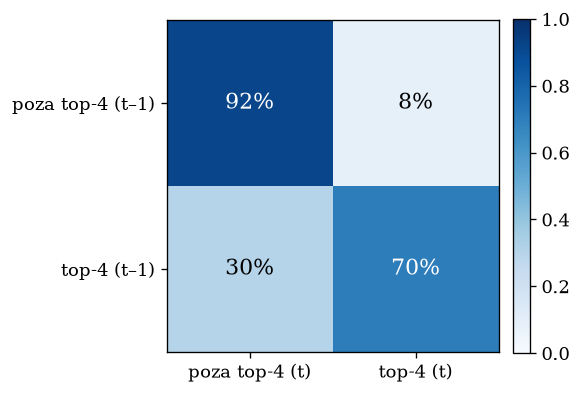

In [14]:
tab = inference.transition_matrix(panel)
print(tab.round(3).to_string())
viz.plot_transition_matrix(tab);

Zapisano wykres: prognoza_plac_stan.png


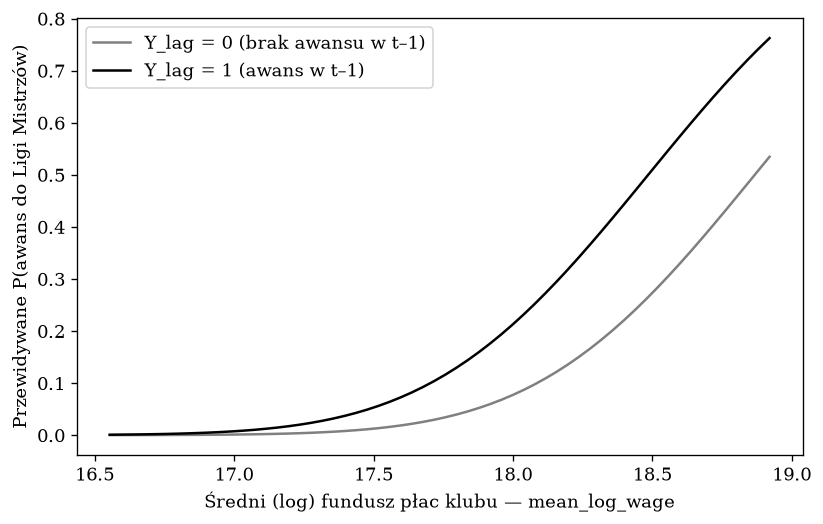

In [15]:
viz.plot_predicted_probability(m_cre, est);

Zapisano wykres: place_a_pozycja.png


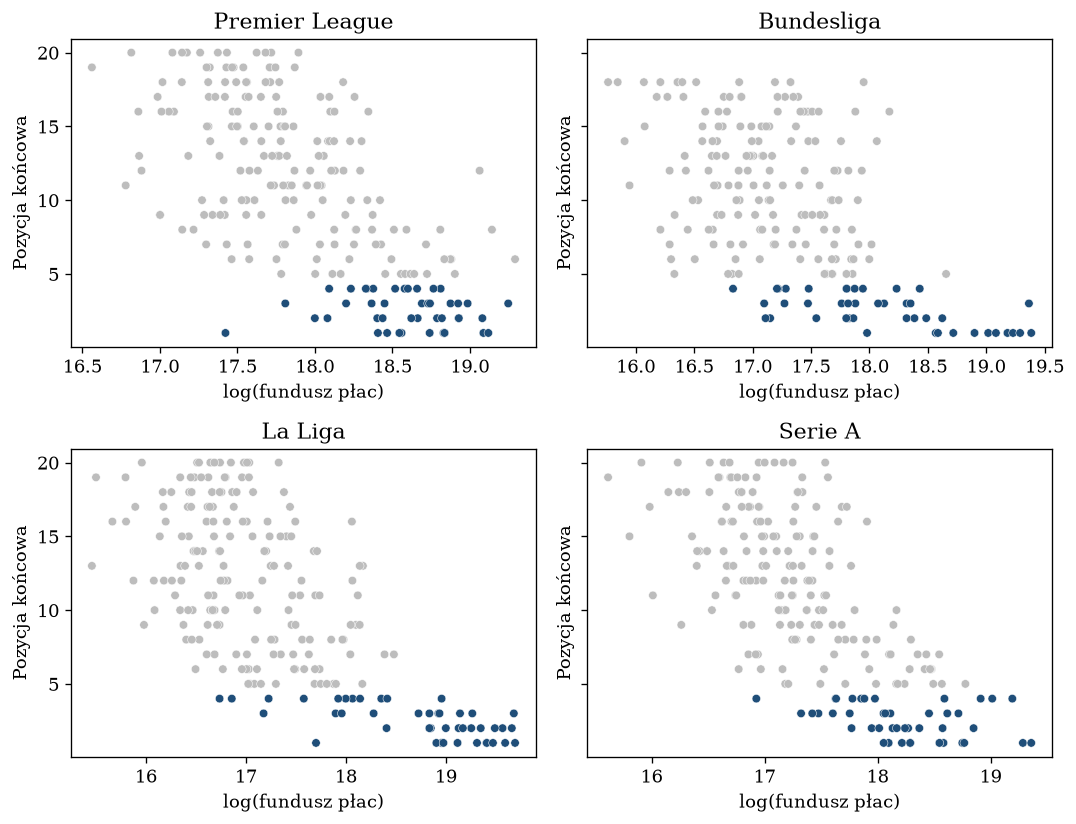

In [16]:
viz.plot_wage_vs_rank(panel);

## 9. Tabele publikacyjne

Cztery tabele zapisywane do `reports/tables/`:

- **referencyjna** — statyczny probit bez zależności stanu,
- **Tabela 2** — model główny CRE: współczynniki i efekty cząstkowe,
- **Tabela 3** — rozbicie per liga z testem różnic,
- **rozszerzenia** — zestawienie wszystkich specyfikacji odpornościowych.

In [17]:
# Tabela referencyjna: statyczny pooled probit
keys_ref = ['log_wage', 'C(league)[T.Premier_League]',
            'C(league)[T.La_Liga]', 'C(league)[T.Serie_A]']
stats_ref = [
    ('Opóźniona zmienna zależna (Y_lag)', 'nie'),
    ('Efekty stałe sezonu / ligi', 'tak'),
    ('Liczba obserwacji (N)', int(m_static.nobs)),
    ('Liczba klubów', int(est['club_id'].nunique())),
    ('Pseudo-R²', viz.fmt(m_static.prsquared)),
]
note_ref = (viz.CLUSTER_NOTE + ' Statyczny pooled probit pomija opóźnioną zmienną '
            'zależną, przez co przeszacowuje rolę bieżącego funduszu płac — efekt '
            'przejmuje na siebie trwałość stanu.')
html_ref = viz.coef_ame_table(
    'Tabela 1. Model referencyjny: statyczny pooled probit',
    m_static, keys_ref, stats_ref, note_ref)
viz.save_table(html_ref, 'tabela_referencyjna.html');

Zapisano tabelę: tabela_referencyjna.html


In [18]:
# Tabela 2. Model glowny CRE: wspolczynniki + efekty czastkowe
keys_cre = ['Y_lag', 'log_wage', 'Y_0', 'mean_log_wage',
            'C(league)[T.Premier_League]', 'C(league)[T.La_Liga]',
            'C(league)[T.Serie_A]']
stats_cre = [
    ('Efekty stałe sezonu', 'tak'),
    ('Efekty stałe ligi', 'tak'),
    ('Liczba obserwacji (N)', int(m_cre.nobs)),
    ('Liczba klubów (klastrów)', int(est['club_id'].nunique())),
    ('Pseudo-R²', viz.fmt(m_cre.prsquared)),
    ('LLR p-value', f'{m_cre.llr_pvalue:.2e}'),
    ('Test Mundlaka (χ²)', f'{viz.fmt(chi2_m)} (p = {p_m:.2e})'),
    ('Link test (p dla kwadratu)', viz.fmt(p_link)),
]
note_cre = (viz.CLUSTER_NOTE + ' AME — przeciętny efekt cząstkowy (różnica dyskretna '
            'dla zmiennych 0/1, pochodna dla ciągłych).')
html_cre = viz.coef_ame_table(
    'Tabela 2. Probit CRE (Wooldridge) dla czterech lig: współczynniki i AME',
    m_cre, keys_cre, stats_cre, note_cre)
viz.save_table(html_cre, 'tabela2_cre_glowny.html');

Zapisano tabelę: tabela2_cre_glowny.html


Zmienna,Współczynnik,Efekt cząstkowy (AME)
Y_lag (kwalifikacja t–1),"0,627***","0,112**"
,"(0,235)","(0,052)"
log_wage (fundusz płac),"0,028","0,004"
,"(0,386)","(0,055)"
Y₀ (warunek początkowy),"0,206","0,031"
,"(0,211)","(0,035)"
x̄ mean_log_wage (Mundlak),"1,614***","0,231***"
,"(0,440)","(0,057)"
Efekt stały: Premier League,"−1,124***","−0,146***"
,"(0,255)","(0,028)"


In [19]:
# Tabela 3. Rozbicie per liga + test roznic
models_lg = [(model.LEAGUE_LABELS[lg], per_league[lg])
             for lg in model.LEAGUE_ORDER if lg in per_league]
keys_lg = ['Y_lag', 'log_wage', 'mean_log_wage', 'Y_0']
stat_rows_lg = [
    ('Efekty stałe sezonu', ['tak'] * len(models_lg)),
    ('Liczba obserwacji (N)', [int(m.nobs) for _, m in models_lg]),
    ('Liczba klubów', [int(est[est['league'] == lg]['club_id'].nunique())
                      for lg in model.LEAGUE_ORDER if lg in per_league]),
    ('Pseudo-R²', [viz.fmt(m.prsquared) for _, m in models_lg]),
]
note_lg = (viz.CLUSTER_NOTE + ' Każdy model zawiera warunek początkowy, średnie '
           'Mundlaka oraz efekty stałe sezonu.<br><strong>Test różnic (Wald)</strong> '
           'zależności stanu między ligami (interakcja Y_lag × liga): '
           f'χ² = {viz.fmt(chi2_w)}, p = {viz.fmt(p_w)}. '
           + ('Brak podstaw do odrzucenia hipotezy o równości współczynników, co '
              'uzasadnia estymację zunifikowaną.' if p_w > 0.05 else
              'Współczynniki różnią się istotnie między ligami.'))
html_lg = viz.multi_model_table(
    'Tabela 3. Osobne modele CRE dla każdej ligi', models_lg, keys_lg,
    stat_rows_lg, note_lg)
viz.save_table(html_lg, 'tabela3_per_liga.html');

Zapisano tabelę: tabela3_per_liga.html


In [20]:
# Tabela rozszerzen i odpornosci
models_ext = [('Główny CRE', m_cre)]
for lab, key in [('+ zmiana trenera', 'mgr'), ('+ saldo transferowe', 'net_spend'),
                 ('+ lead płac (egzo.)', 'wage_lead'),
                 ('Wartość rynkowa', 'market_value'),
                 ('Podpróba zbalans.', 'balanced')]:
    if key in ext:
        models_ext.append((lab, ext[key]))

keys_ext = ['Y_lag', 'log_wage', 'mean_log_wage', 'log_mv', 'mean_log_mv',
            'mgr_change', 'net_spend_m', 'mean_net_spend_m', 'log_wage_lead', 'Y_0']
stat_rows_ext = [
    ('Efekty stałe sezonu / ligi', ['tak'] * len(models_ext)),
    ('Liczba obserwacji (N)', [int(m.nobs) for _, m in models_ext]),
    ('Pseudo-R²', [viz.fmt(m.prsquared) for _, m in models_ext]),
]
note_ext = (viz.CLUSTER_NOTE + ' Wszystkie modele zawierają warunek początkowy, '
            'średnie Mundlaka oraz efekty stałe ligi i sezonu. Rozszerzenie '
            f'„beniaminek” pominięto — perfekcyjna separacja ({prom_top} z {n_prom}) '
            'uniemożliwia oszacowanie współczynnika. We wszystkich specyfikacjach '
            'współczynnik zależności stanu (Y_lag) pozostaje dodatni i istotny.')
html_ext = viz.multi_model_table(
    'Tabela 4. Rozszerzenia i odporność modelu', models_ext, keys_ext,
    stat_rows_ext, note_ext)
viz.save_table(html_ext, 'tabela_rozszerzenia.html');

Zapisano tabelę: tabela_rozszerzenia.html


Zmienna,Główny CRE,+ zmiana trenera,+ saldo transferowe,+ lead płac (egzo.),Wartość rynkowa,Podpróba zbalans.
Y_lag (kwalifikacja t–1),"0,627***","0,755***","0,753***","0,644***","0,865***","0,631**"
,"(0,235)","(0,229)","(0,241)","(0,244)","(0,209)","(0,257)"
log_wage (fundusz płac),"0,028","0,131","0,053","−0,935*",—,"−0,096"
,"(0,386)","(0,389)","(0,386)","(0,489)",,"(0,492)"
x̄ mean_log_wage (Mundlak),"1,614***","1,554***","1,550***","1,683***",—,"1,667***"
,"(0,440)","(0,455)","(0,437)","(0,509)",,"(0,594)"
log_mv (wartość rynkowa),—,—,—,—,"0,016",—
,,,,,"(0,205)",
x̄ mean_log_mv (Mundlak),—,—,—,—,"1,452***",—
,,,,,"(0,271)",


## Wnioski

- **Zależność stanu jest realna i istotna.** `Y_lag` = +0,627 (p = 0,008); w przeliczeniu
  na efekt cząstkowy sam awans w poprzednim sezonie podnosi prawdopodobieństwo awansu
  o około 11 punktów procentowych, przy niezmienionym poziomie finansów.
- **Bieżący fundusz płac sam nie wyjaśnia niczego.** W modelu CRE `log_wage` jest
  nieistotny (+0,028, p = 0,942) — cały efekt finansowy przechodzi przez średnią
  Mundlaka (+1,614, p < 0,001). Liczy się trwały poziom zamożności klubu, nie
  jednorazowe podniesienie wydatków.
- **Model statyczny myli te dwa kanały.** Bez `Y_lag` współczynnik przy `log_wage`
  rośnie do +1,901 — bieżące płace przejmują to, co w rzeczywistości jest trwałością
  pozycji i trwałą zamożnością.
- **CRE jest konieczne.** Test Mundlaka odrzuca H0 (χ² = 14,75, p = 0,0006), więc efekt
  klubu jest skorelowany z regresorami i zwykły RE byłby obciążony.
- **Trwałość jest wspólna dla czterech lig.** Test Walda na interakcjach `Y_lag × liga`
  nie odrzuca równości (χ² = 1,18, p = 0,757), co uzasadnia estymację zunifikowaną.
- **Ograniczenie, które trzeba wymienić wprost:** test ścisłej egzogeniczności **wypada
  negatywnie** dla płac (lead `log_wage(t+1)`, p = 0,005). Fundusz płac reaguje na
  przeszłe wyniki, więc oszacowania należy czytać jako zależności warunkowe, nie efekty
  przyczynowe. Dla salda transferowego feedbacku nie wykryto (p = 0,108).